# Importing Libraries

In [24]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd

# Load in Bandpasses

## CHEOPS

In [25]:
# load in bandpass
bp_CHEOPS = np.array(pd.read_csv('CHEOPS_bandpass.csv')['PASSBAND'])
λ_CHEOPS = [3300, 11000]    # Wavelength range [Angstrom] # use range in banpass file to correctly select from bandpass 

## TESS

In [26]:
# load in bandpass
bp_TESS = np.array(pd.read_csv('tess-response-function-v2.0.csv', skiprows=6)[' lambda Transmission'])
λ_TESS = λ_TESS=[3000, 20000]    # Wavelength range [Angstrom] # use range in bandpass file to correctly select from bandpass 

# Load in Data and Plot

In [27]:
# load in CHEOPS
CHEOPS_spec = [] # empty list to store spectra for psi values
CHEOPS_lam = [] # empty list to store spectra for psi values 
for sheet in np.linspace(0, 3, 6): 
    data = pd.read_excel("CHEOPS_spectra_100_3_6.xlsx", sheet_name = str(round(sheet, 1)))
    CHEOPS_spec.append(np.array(data[0]))
CHEOPS_lam.append(np.array(data['Unnamed: 0']))

In [28]:
# load in TESS
TESS_spec = [] # empty list to store spectra for psi values
TESS_lam = [] # empty list to store spectra for psi values 
for sheet in np.linspace(0, 3, 6): 
    data = pd.read_excel("TESS_spectra_100_3_6.xlsx", sheet_name = str(round(sheet, 1)))
    TESS_spec.append(np.array(data[0]))
TESS_lam.append(np.array(data['Unnamed: 0']))

In [29]:
# define plotting function for all spectra and normalise
def plot_spec(specs, λ, lam, bp, psi, mission):
    # set plot params
    plt.figure(figsize=(20,10))
    plt.rcParams['xtick.labelsize'] = 15
    plt.rcParams['ytick.labelsize'] = 15
    
    # create list to store spectra with bandpass applied for normalisation 
    spectra_plot = []

    for i in np.arange(0, len(specs), 1): 
        # apply bandpass 
        # assign each lambda value to nearest integer and take bandpass value 
        args = np.searchsorted(np.arange(λ[0], λ[1]+0.1, 10), lam)[0]
        bp_use = bp[args-1] # -1 to shift back to correct bandpass value 
        spectra_plot.append(specs[i]*bp_use)

        # plot data 
        plt.plot(lam[0], spectra_plot[i]/spectra_plot[0], label=r'$\phi$ = ' + str(round(psi[i], 1)))

    # add additional plot features
    plt.grid(True)
    plt.xlabel(r'$\lambda (\AA)$', fontsize=20)
    plt.ylabel('Spectral radiance (erg m$^{-2}$ s$^{-1}$ $\mu$m$^{-1}$)', fontsize=20)
    plt.title(mission + ' Spectra', fontsize=30)
    plt.legend(fontsize=15);

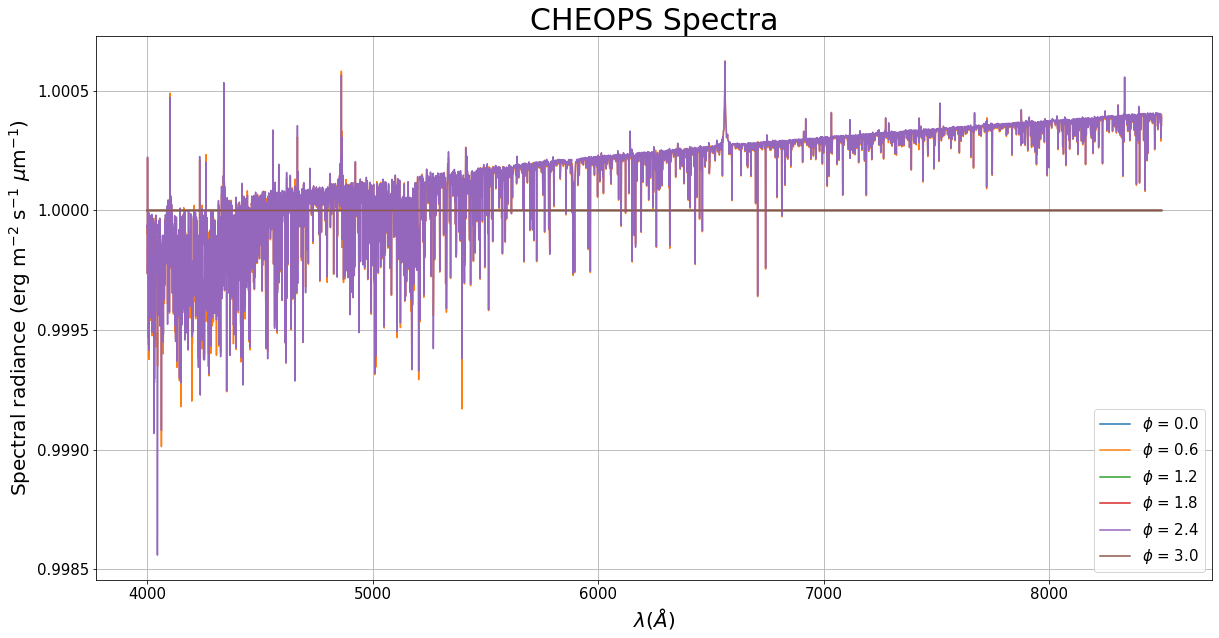

In [30]:
plot_spec(CHEOPS_spec, λ_CHEOPS, CHEOPS_lam, bp_CHEOPS, np.linspace(0, 3, 6), 'CHEOPS')

<ipython-input-29-631ef96f00f8>:19: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(lam[0], spectra_plot[i]/spectra_plot[0], label=r'$\phi$ = ' + str(round(psi[i], 1)))
<ipython-input-29-631ef96f00f8>:19: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(lam[0], spectra_plot[i]/spectra_plot[0], label=r'$\phi$ = ' + str(round(psi[i], 1)))
<ipython-input-29-631ef96f00f8>:19: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(lam[0], spectra_plot[i]/spectra_plot[0], label=r'$\phi$ = ' + str(round(psi[i], 1)))
<ipython-input-29-631ef96f00f8>:19: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(lam[0], spectra_plot[i]/spectra_plot[0], label=r'$\phi$ = ' + str(round(psi[i], 1)))
<ipython-input-29-631ef96f00f8>:19: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(lam[0], spectra_plot[i]/spectra_plot[0], label=r'$\phi$ = ' + str(round(psi[i], 1)))
<ipython-input-29-631ef96f00f8>:19: RuntimeWarning: inv

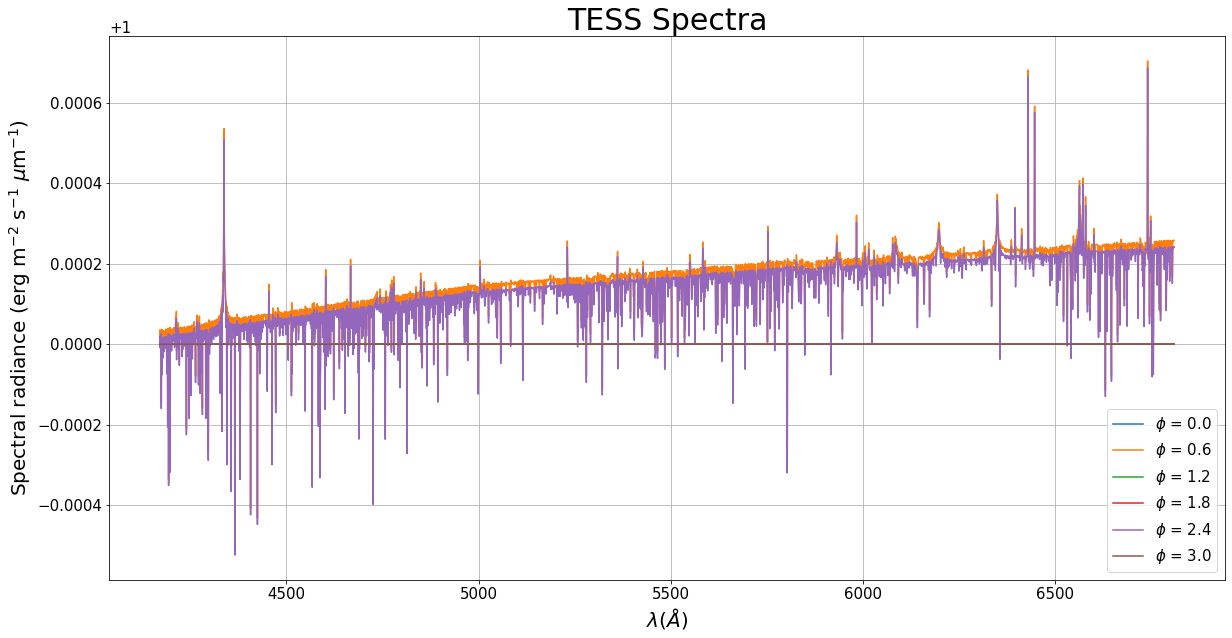

In [31]:
plot_spec(TESS_spec, λ_TESS, TESS_lam, bp_TESS, np.linspace(0, 3, 6), 'TESS')

In [32]:
print()